In [ ]:

# Seeded MOBO run
from tqdm import tqdm
import random

# Multi-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.models import ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import SumMarginalLogLikelihood
# from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
# from botorch.acquisition.joint_entropy_search import qJointEntropySearch
# from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
# from botorch.acquisition.multi_objective import qLogNParEGO
from botorch.acquisition.multi_objective.predictive_entropy_search import qMultiObjectivePredictiveEntropySearch
from botorch.acquisition.multi_objective.joint_entropy_search import qLowerBoundMultiObjectiveJointEntropySearch
from botorch.acquisition.multi_objective.max_value_entropy_search import qLowerBoundMultiObjectiveMaxValueEntropySearch
from botorch.acquisition.multi_objective.parego import qLogNParEGO
from botorch.optim import optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)


acquf_list = [
    'qPredictiveEntropySearch',
    'qJointEntropySearch',
    'qMaxValueEntropy',
    'qLogNParEGO',
    # 'qHypervolumeKnowledgeGradient'
]
    
import pandas as pd
from sklearn.model_selection import train_test_split
import torch

dataset = "SDL_case_studies/inorganic_materials/case1"

inputs = pd.read_csv(f'{dataset}/dataset/inputs.csv')
outputs = pd.read_csv(f'{dataset}/dataset/outputs.csv')
total = pd.concat([inputs, outputs], axis=1)


train_X_df, test_X_df, train_y_df, test_y_df = train_test_split(inputs,outputs, test_size=0.9, random_state=42)

train_X = torch.tensor(train_X_df.to_numpy())
test_X = torch.tensor(test_X_df.to_numpy())

train_y = torch.tensor(train_y_df.to_numpy())
test_y = torch.tensor(test_y_df.to_numpy())

external_test_X = torch.tensor(external_test_X_df.to_numpy())
external_test_y = torch.tensor(external_test_y_df.to_numpy())

X_tensor = torch.tensor(inputs.to_numpy())
y_tensor = torch.tensor(outputs.to_numpy())

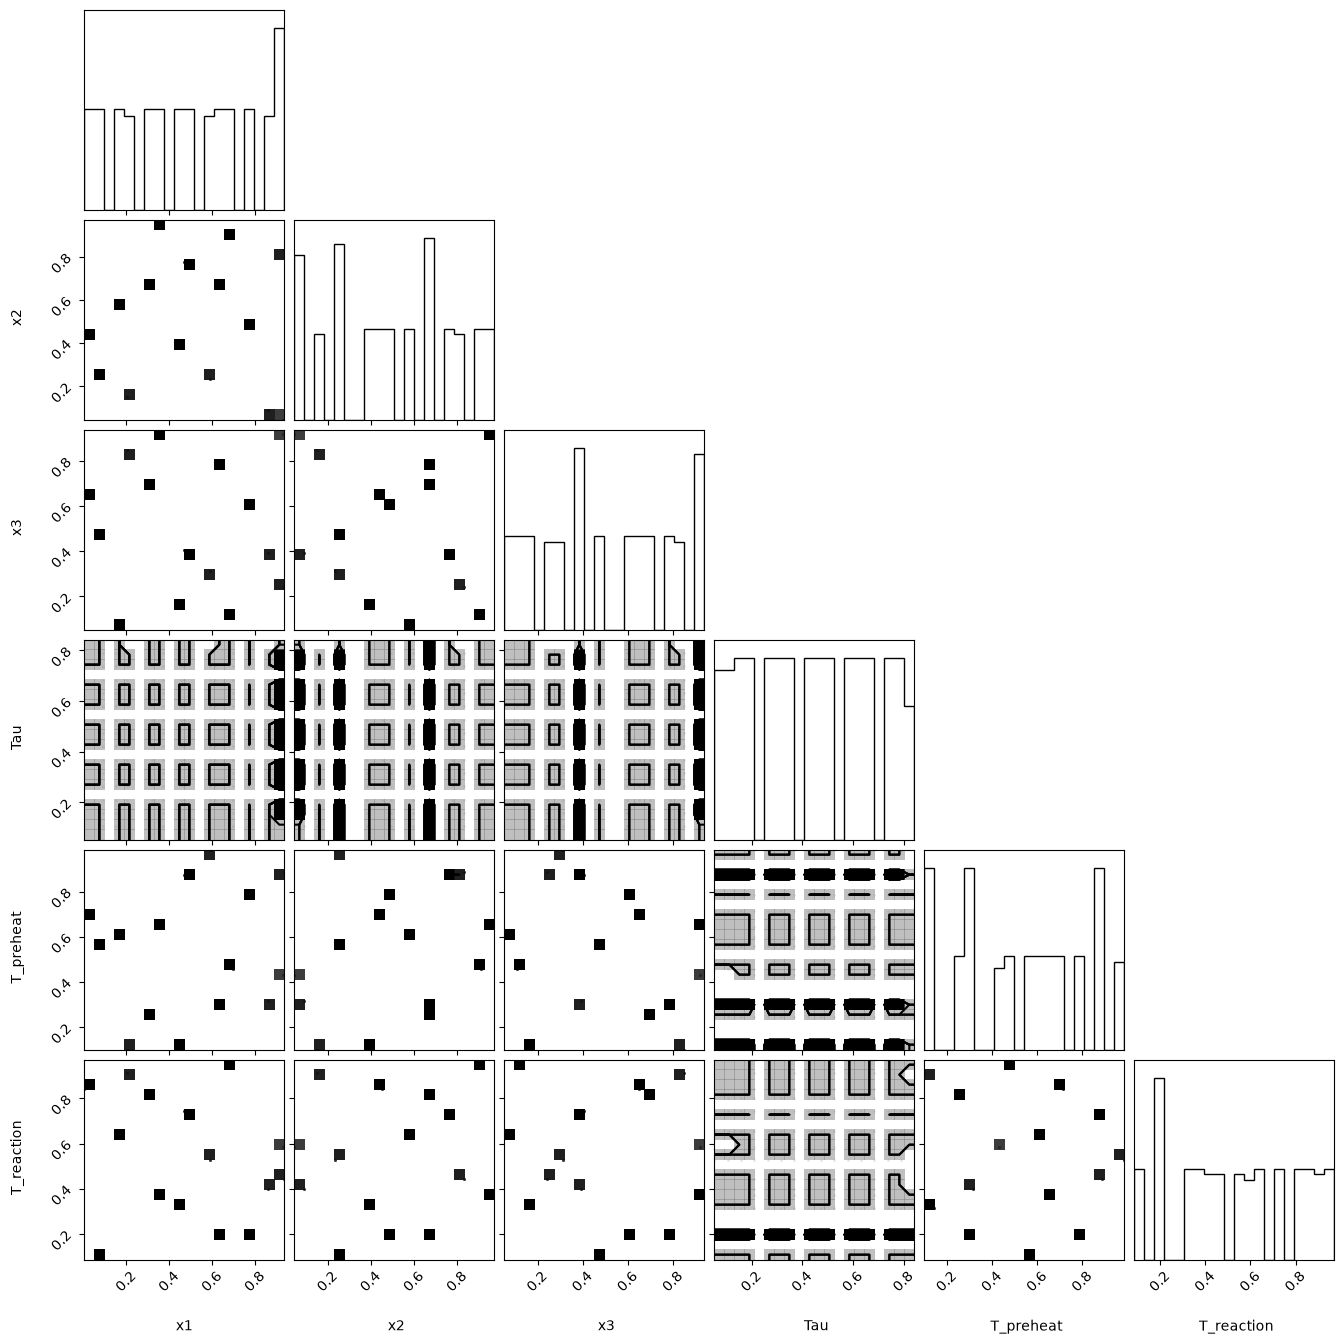

In [20]:
import corner

fig = corner.corner(inputs, labels=inputs.columns)

In [8]:
# Single-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
from botorch.acquisition.joint_entropy_search import qJointEntropySearch
from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.optim import optimize_acqf, optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn


acquf = 'qMaxValueEntropy'
kernel = 'RBFKernel'
break_after_finding_optimum = True


acquf_list = [
    'qPredictiveEntropySearch',
    'qJointEntropySearch',
    'qMaxValueEntropy'
]

kernel_list = [
    "keops",
    "Kernel",
    "ArcKernel",
    "AdditiveKernel",
    "AdditiveStructureKernel",
    "ConstantKernel",
    "CylindricalKernel",
    "MultiDeviceKernel",
    "CosineKernel",
    "DistributionalInputKernel",
    "GaussianSymmetrizedKLKernel",
    "GridKernel",
    "GridInterpolationKernel",
    "HammingIMQKernel",
    "IndexKernel",
    "InducingPointKernel",
    "LCMKernel",
    "LinearKernel",
    "MaternKernel",
    "MultitaskKernel",
    "NewtonGirardAdditiveKernel",
    "PeriodicKernel",
    "PiecewisePolynomialKernel",
    "PolynomialKernel",
    "PolynomialKernelGrad",
    "ProductKernel",
    "ProductStructureKernel",
    "RBFKernel",
    "RFFKernel",
    "RBFKernelGrad",
    "RBFKernelGradGrad",
    "RQKernel",
    "ScaleKernel",
    "SpectralDeltaKernel",
    "SpectralMixtureKernel",
    "Matern52KernelGrad",
]


torch.manual_seed(42)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

optimisations = len(test_X)

target_preds = []

best_idx_global = test_y[:, 0].argmax()
global_optimal_inputs = test_X[best_idx_global].unsqueeze(0)
global_optimal_outputs = test_y[best_idx_global, 0].reshape(1, 1)

for i in tqdm(range(optimisations), total=optimisations, desc='Optimising'):
    
    # Calculate optimal inputs and outputs 
    # for Entropy-based acquisition functions
    best_idx = train_y[:, 0].argmax()

    optimal_inputs = train_X[best_idx].unsqueeze(0)
    optimal_outputs = train_y[best_idx, 0].reshape(1, 1)


    model=SingleTaskGP(train_X,train_y[:, 0].unsqueeze(1),
                    outcome_transform=Standardize(m=1),
                    # covar_module=ScaleKernel(LinearKernel(train_X.shape[-1])),
                    )
    
    
    # Load chosen acquisition function
    if acquf == 'qPredictiveEntropySearch':
        acq = qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)
    elif acquf == 'qJointEntropySearch':
        acq = qJointEntropySearch(model=model, optimal_inputs=optimal_inputs, optimal_outputs=optimal_outputs)
    elif acquf == 'qMaxValueEntropy':
        acq = qMaxValueEntropy(model=model, candidate_set=train_X)
    else:
        print('Acquisition function not in list')
        break


    fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood,model))




    new_X,_=optimize_acqf_discrete( # Discrete acqf required to confine model to known experiments
                                    acq_function=acq, 
                                    choices=test_X,
                                    q=1,
    )


    # Remove selected data point from test, add to train
    hit = (test_X == new_X).all(dim=1)
    
    if test_y[hit][:, 0] == global_optimal_outputs.squeeze(0):
        print(f'Optimised after {i} iterations')
        if break_after_finding_optimum:
            break
    
    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))

    test_X = test_X[~hit]
    test_y = test_y[~hit]
    
    
    target_preds.append(model.posterior(external_test_X).mean) # Make predictions for external test set
    

Optimising:   7%|▋         | 14/211 [00:01<00:21,  9.18it/s]

Optimised after 14 iterations


/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/torch/nn/modules/loss.py:133: UserWarning: Using a target size (torch.Size([22, 2])) that is different to the input size (torch.Size([22, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)


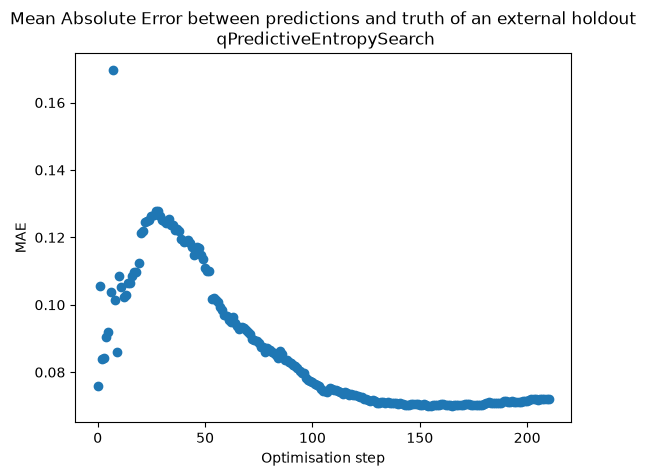

In [7]:
import matplotlib.pyplot as plt

MAEs = [MAE(pred, external_test_y).detach() for pred in target_preds]
plt.scatter(range(len(MAEs)), MAEs)
plt.title(f'Mean Absolute Error between model predictions and truth of an external holdout\n {outputs.columns[i]} \n {acquf}')
plt.xlabel('Optimisation step')
plt.ylabel('MAE')
plt.show()

In [2]:
# Multi-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.models import ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import SumMarginalLogLikelihood
from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
from botorch.acquisition.joint_entropy_search import qJointEntropySearch
from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.optim import optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn


acquf = 'qJointEntropySearch'
kernel = 'RBFKernel'
break_after_finding_optimum = True


# torch.manual_seed(42)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

optimisations = len(test_X)
# optimisations = 200

target_preds = []

best_idx_global = test_y[:, :].argmax()
global_optimal_inputs = test_X[best_idx_global].unsqueeze(0)
global_optimal_outputs = test_y[best_idx_global, :]

for iter in tqdm(range(optimisations), total=optimisations, desc='Optimising'):
    
    # Calculate optimal inputs and outputs for Entropy-based acquisition functions

    models = []
    
    for feature in range(train_y.shape[-1]):
        best_idx = train_y[:, feature].argmax()

        optimal_inputs = train_X[best_idx].unsqueeze(0)
        optimal_outputs = train_y[best_idx, feature].reshape(1, 1)
        
        model=SingleTaskGP(train_X,train_y[:, feature].unsqueeze(1),
                        outcome_transform=Standardize(m=1),
                        # covar_module=ScaleKernel(LinearKernel(train_X.shape[-1])),
                        )
        models.append(model)
    
        # Load chosen acquisition function
        if acquf == 'qPredictiveEntropySearch':
            acq = qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)
        elif acquf == 'qJointEntropySearch':
            acq = qJointEntropySearch(model=model, optimal_inputs=optimal_inputs, optimal_outputs=optimal_outputs)
        elif acquf == 'qMaxValueEntropy':
            acq = qMaxValueEntropy(model=model, candidate_set=train_X)
        else:
            print('Acquisition function not in list')
            break


    model = ModelListGP(*models)

    fit_gpytorch_mll(SumMarginalLogLikelihood(model.likelihood,model))




    new_X,_=optimize_acqf_discrete( # Discrete acqf required to confine model to known experiments
                                    acq_function=acq, 
                                    choices=test_X,
                                    q=1,
    )


    # Remove selected data point from test, add to train
    hit = (test_X == new_X).all(dim=1)

    if torch.any(test_y[hit] == global_optimal_outputs):
        print(f'Optimised after {iter} iterations')
        if break_after_finding_optimum:
            break


    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))

    test_X = test_X[~hit]
    test_y = test_y[~hit]

    target_preds.append(model.posterior(external_test_X).mean) # Make predictions for external test set
    

/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Optimising:  91%|█████████ | 191/211 [00:56<00:05,  3.41it/s]

Optimised after 191 iterations


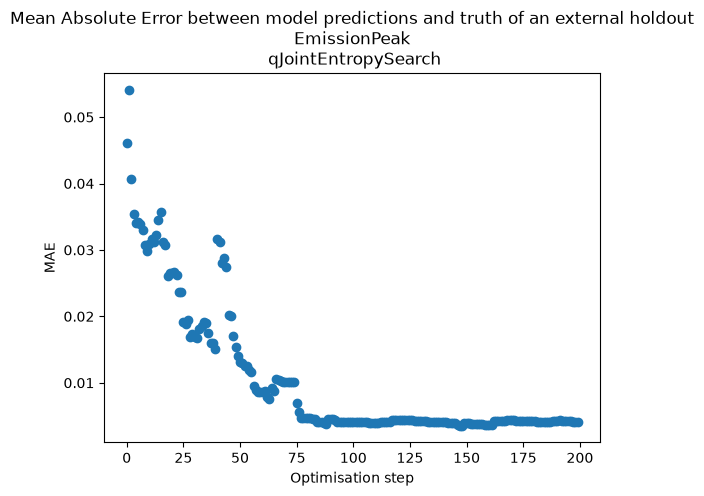

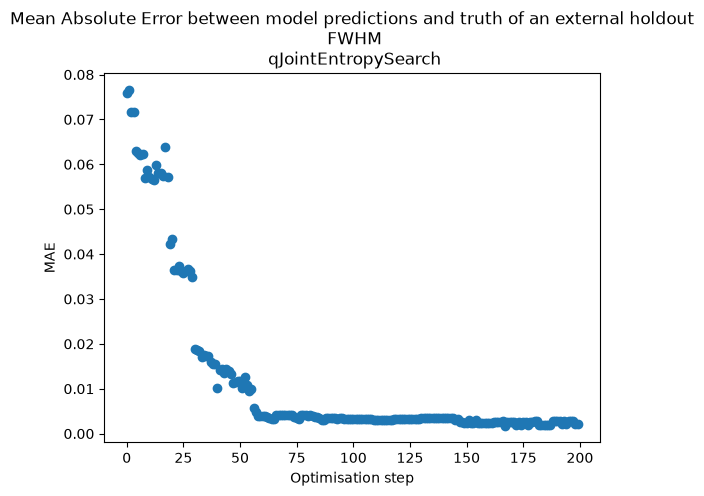

In [3]:
import matplotlib.pyplot as plt

for i in range(test_y.shape[-1]):
    MAEs = [MAE(pred[:, i], external_test_y[:, i]).detach() for pred in target_preds]
    plt.scatter(range(len(MAEs)), MAEs)
    plt.title(f'Mean Absolute Error between model predictions and truth of an external holdout\n {outputs.columns[i]} \n {acquf}')
    plt.xlabel('Optimisation step')
    plt.ylabel('MAE')
    plt.show()

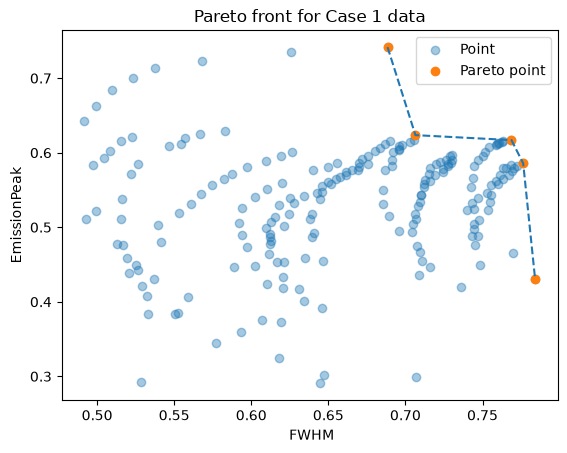

In [68]:
import matplotlib.pyplot as plt
from botorch.utils.multi_objective.pareto import is_non_dominated

pareto_mask = is_non_dominated(test_y, maximize=True)
pareto_y = test_y[pareto_mask]

all_y = test_y.detach().numpy()
front = pareto_y.detach().numpy()
front = front[front[:, 1].argsort()]

plt.scatter(all_y[:, 1], all_y[:, 0], alpha=0.4, label="Point")
plt.scatter(front[:, 1], front[:, 0], label="Pareto point")
plt.plot(front[:, 1], front[:, 0], "--")
plt.xlabel(f"{outputs.columns[-1]}")
plt.ylabel(f"{outputs.columns[0]}")
plt.legend()
plt.title('Pareto front for Case 1 data')
plt.show()

In [104]:

# Seeded MOBO run
from tqdm import tqdm
import random

# Multi-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.models import ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import SumMarginalLogLikelihood
# from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
# from botorch.acquisition.joint_entropy_search import qJointEntropySearch
# from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.acquisition.multi_objective.logei import qLogExpectedHypervolumeImprovement
from botorch.acquisition.multi_objective.predictive_entropy_search import qMultiObjectivePredictiveEntropySearch
from botorch.acquisition.multi_objective.joint_entropy_search import qLowerBoundMultiObjectiveJointEntropySearch
from botorch.acquisition.multi_objective.max_value_entropy_search import qLowerBoundMultiObjectiveMaxValueEntropySearch
from botorch.utils.multi_objective.box_decompositions.non_dominated import NondominatedPartitioning
from botorch.acquisition.multi_objective.parego import qLogNParEGO
from botorch.optim import optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch.utils.multi_objective.box_decompositions.dominated import DominatedPartitioning
from botorch.acquisition.monte_carlo import qUpperConfidenceBound
from botorch.acquisition.objective import GenericMCObjective
from botorch.sampling.normal import SobolQMCNormalSampler

seeds = [random.randint(1, 1000000) for i in range(10)]
acquf_list = [
    'qUCB',
    'qPredictiveEntropySearch',
    'qJointEntropySearch',
    'qMaxValueEntropy',
    'qLogNParEGO',
    'qLogEHVI'
]

seeded_runs = {}
for seed in seeds:
    print(f'Optimising for seed {seed}')
    
    import pandas as pd
    from sklearn.model_selection import train_test_split
    import torch

    dataset = "SDL_case_studies/inorganic_materials/case1"

    inputs = pd.read_csv(f'{dataset}/dataset/inputs.csv')
    outputs = pd.read_csv(f'{dataset}/dataset/outputs.csv')
    total = pd.concat([inputs, outputs], axis=1)


    train_X_df, test_X_df, train_y_df, test_y_df = train_test_split(inputs,outputs, test_size=0.9, random_state=42)
    train_X_df, external_test_X_df, train_y_df, external_test_y_df = train_test_split(train_X_df, train_y_df, test_size=0.9, random_state=42) # Create external test set for model evaluation
    
    



    # acquf = 'qJointEntropySearch'
    kernel = 'RBFKernel'
    break_after_finding_optimum = True
    use_elbow = True
    

    acquf_results_dict = {}
    
    for acquf in acquf_list:
        train_X = torch.tensor(train_X_df.to_numpy())
        test_X = torch.tensor(test_X_df.to_numpy())

        train_y = torch.tensor(train_y_df.to_numpy())
        test_y = torch.tensor(test_y_df.to_numpy())

        external_test_X = torch.tensor(external_test_X_df.to_numpy())
        external_test_y = torch.tensor(external_test_y_df.to_numpy())

        X_tensor = torch.tensor(inputs.to_numpy())
        y_tensor = torch.tensor(outputs.to_numpy())
        
        torch.manual_seed(seed)
        MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

        optimisations = len(test_X)

        target_preds = []

        y_min = train_y.min(dim=0).values
        y_range = train_y.max(dim=0).values - y_min
        ref_point = y_min - 0.1 * y_range.clamp_min(1e-8)


        global_pareto_X = test_X[is_non_dominated(test_y, maximize=True)]
        global_pareto_outputs = test_y[is_non_dominated(test_y, maximize=True)]
        
        if use_elbow:
            # Normalise Pareto objectives
            y_min = global_pareto_outputs.min(dim=0).values
            y_max = global_pareto_outputs.max(dim=0).values
            y_norm = (global_pareto_outputs - y_min) / (y_max - y_min).clamp_min(1e-8)

            # Find balanced Pareto solution (closest to ideal point)
            distances = torch.linalg.norm(1 - y_norm, dim=1)
            elbow_idx = torch.argmin(distances)

            elbow_input = global_pareto_X[elbow_idx]
            elbow_output = global_pareto_outputs[elbow_idx]
            


        for iter in tqdm(range(optimisations), total=optimisations, desc=f"Optimising for acqf {acquf}"):
            models = []
            for objective in range(train_y.shape[-1]):
                gp = SingleTaskGP(
                    train_X,
                    train_y[:, objective : objective + 1],
                    outcome_transform=Standardize(m=1),
                )
                models.append(gp)

            model = ModelListGP(*models)
            mll = SumMarginalLogLikelihood(model.likelihood, model)
            fit_gpytorch_mll(mll)

            pareto_mask = is_non_dominated(train_y, maximize=True)
            pareto_inputs = train_X[pareto_mask]
            pareto_outputs = train_y[pareto_mask]

            partitioning = DominatedPartitioning(
                ref_point=ref_point,
                Y=pareto_outputs,
            )
            hypercell_bounds = partitioning.get_hypercell_bounds().unsqueeze(0)

            if acquf == "qPredictiveEntropySearch":
                acq = qMultiObjectivePredictiveEntropySearch(
                    model=model,
                    pareto_sets=pareto_inputs.unsqueeze(0),
                )
            elif acquf == "qJointEntropySearch":
                acq = qLowerBoundMultiObjectiveJointEntropySearch(
                    model=model,
                    pareto_sets=pareto_inputs.unsqueeze(0),
                    pareto_fronts=pareto_outputs.unsqueeze(0),
                    hypercell_bounds=hypercell_bounds,
                )
            elif acquf == "qMaxValueEntropy":
                acq = qLowerBoundMultiObjectiveMaxValueEntropySearch(
                    model=model,
                    hypercell_bounds=hypercell_bounds,
                )
            elif acquf == 'qLogNParEGO':
                acq = qLogNParEGO(
                    model=model,
                    X_baseline=train_X,
                )
            elif acquf == 'qLogEHVI':
                partitioning = NondominatedPartitioning(
                    ref_point=ref_point,
                    Y=pareto_outputs,
                )

                acq = qLogExpectedHypervolumeImprovement(
                    model=model,
                    ref_point=ref_point,
                    partitioning=partitioning,
                )
            elif acquf == 'qUCB':
                weights = torch.distributions.Dirichlet(
                    torch.ones(train_y.shape[-1], dtype=train_y.dtype)
                ).sample().to(train_y.device)

                objective = GenericMCObjective(
                    lambda Y, X=None: (Y * weights).sum(dim=-1)
                )
                
                acq = qUpperConfidenceBound(
                    model=model,
                    beta=0.2,
                    sampler=SobolQMCNormalSampler(
                        sample_shape=torch.Size([128])
                    ),
                    objective=objective,
                )
            else:
                raise ValueError(f"Unknown acquisition function: {acquf}")

            new_X, _ = optimize_acqf_discrete(
                acq_function=acq,
                choices=test_X,
                q=1,
            )

            hit = (test_X == new_X).all(dim=1)

            if use_elbow == True:
                if (elbow_input == new_X.reshape(-1)).all(dim=-1).any():
                    print(f"Found a test-set Pareto point after {iter + 1} iterations")
                    acquf_results_dict[acquf] = iter + 1
                    if break_after_finding_optimum:
                        break
            else:  
                if (global_pareto_X == new_X.reshape(-1)).all(dim=-1).any():
                    print(f"Found a test-set Pareto point after {iter + 1} iterations")
                    acquf_results_dict[acquf] = iter + 1
                    if break_after_finding_optimum:
                        break
                

            train_X = torch.cat((train_X, test_X[hit]))
            train_y = torch.cat((train_y, test_y[hit]))
            test_X = test_X[~hit]
            test_y = test_y[~hit]

            target_preds.append(model.posterior(external_test_X).mean)
            
        seeded_runs[seed] = acquf_results_dict
            

Optimising for seed 261476


Optimising for acqf qUCB:   5%|▌         | 11/211 [00:01<00:25,  7.82it/s]


Found a test-set Pareto point after 12 iterations


Optimising for acqf qPredictiveEntropySearch:   2%|▏         | 5/211 [00:00<00:35,  5.73it/s]


Found a test-set Pareto point after 6 iterations


Optimising for acqf qJointEntropySearch:   2%|▏         | 4/211 [00:00<00:21,  9.48it/s]


... (111 outputs left out)

Optimising for acqf qLogNParEGO:   4%|▍         | 9/211 [00:01<00:25,  7.79it/s]


Found a test-set Pareto point after 10 iterations


Optimising for acqf qLogEHVI:   1%|▏         | 3/211 [00:00<00:21,  9.88it/s]

Found a test-set Pareto point after 4 iterations


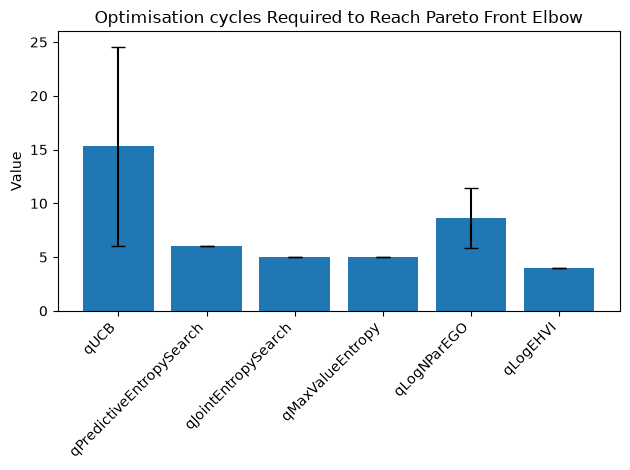

In [108]:
import numpy as np
import matplotlib.pyplot as plt

acquisitions = list(list(seeded_runs.values())[0].keys())
values = {
    name: [run[name] for run in seeded_runs.values()]
    for name in acquisitions
}

means = [np.mean(values[name]) for name in acquisitions]
stds = [np.std(values[name], ddof=1) for name in acquisitions]

plt.bar(acquisitions, means, yerr=stds, capsize=5)
if use_elbow:
    plt.title('Optimisation cycles Required to Reach Pareto Front Elbow')
else:
    plt.title('Optimisation cycles Required to Reach Pareto Front')
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.tight_layout()
plt.ylim((0, 26))
plt.show()

In [ ]:

# Seeded MOBO run
from tqdm import tqdm
import random

# Multi-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.models import ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import SumMarginalLogLikelihood
# from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
# from botorch.acquisition.joint_entropy_search import qJointEntropySearch
# from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
# from botorch.acquisition.multi_objective import qLogNParEGO
from botorch.acquisition.multi_objective.predictive_entropy_search import qMultiObjectivePredictiveEntropySearch
from botorch.acquisition.multi_objective.joint_entropy_search import qLowerBoundMultiObjectiveJointEntropySearch
from botorch.acquisition.multi_objective.max_value_entropy_search import qLowerBoundMultiObjectiveMaxValueEntropySearch
from botorch.acquisition.multi_objective.parego import qLogNParEGO
from botorch.optim import optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)

seeds = [random.randint(1, 1000000) for i in range(10)]
acquf_list = [
    'qPredictiveEntropySearch',
    'qJointEntropySearch',
    'qMaxValueEntropy',
    'qLogNParEGO',
    # 'qHypervolumeKnowledgeGradient'
]

seeded_runs = {}


import pandas as pd
from sklearn.model_selection import train_test_split
import torch

dataset = "SDL_case_studies/inorganic_materials/case1"

inputs = pd.read_csv(f'{dataset}/dataset/inputs.csv')
outputs = pd.read_csv(f'{dataset}/dataset/outputs.csv')
total = pd.concat([inputs, outputs], axis=1)


train_X_df, test_X_df, train_y_df, test_y_df = train_test_split(inputs,outputs, test_size=0.9, random_state=42)
train_X_df, external_test_X_df, train_y_df, external_test_y_df = train_test_split(train_X_df, train_y_df, test_size=0.9, random_state=42) # Create external test set for model evaluation





# acquf = 'qJointEntropySearch'
kernel = 'RBFKernel'
break_after_finding_optimum = True
use_elbow = False


acquf_results_dict = {}


train_X = torch.tensor(train_X_df.to_numpy())
test_X = torch.tensor(test_X_df.to_numpy())

train_y = torch.tensor(train_y_df.to_numpy())
test_y = torch.tensor(test_y_df.to_numpy())

external_test_X = torch.tensor(external_test_X_df.to_numpy())
external_test_y = torch.tensor(external_test_y_df.to_numpy())

X_tensor = torch.tensor(inputs.to_numpy())
y_tensor = torch.tensor(outputs.to_numpy())

torch.manual_seed(seed)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

optimisations = len(test_X)

target_preds = []

y_min = train_y.min(dim=0).values
y_range = train_y.max(dim=0).values - y_min
ref_point = y_min - 0.1 * y_range.clamp_min(1e-8)


global_pareto_X = test_X[is_non_dominated(test_y, maximize=True)]
global_pareto_outputs = test_y[is_non_dominated(test_y, maximize=True)]

if use_elbow:
    # Normalise Pareto objectives
    y_min = global_pareto_outputs.min(dim=0).values
    y_max = global_pareto_outputs.max(dim=0).values
    y_norm = (global_pareto_outputs - y_min) / (y_max - y_min).clamp_min(1e-8)

    # Find balanced Pareto solution (closest to ideal point)
    distances = torch.linalg.norm(1 - y_norm, dim=1)
    elbow_idx = torch.argmin(distances)

    elbow_input = global_pareto_X[elbow_idx]
    elbow_output = global_pareto_outputs[elbow_idx]
    


for iter in tqdm(range(optimisations), total=optimisations, desc=f"Optimising for acqf {acquf}"):
    models = []
    for objective in range(train_y.shape[-1]):
        gp = SingleTaskGP(
            train_X,
            train_y[:, objective : objective + 1],
            outcome_transform=Standardize(m=1),
        )
        models.append(gp)

    model = ModelListGP(*models)
    mll = SumMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)

    pareto_mask = is_non_dominated(train_y, maximize=True)
    pareto_inputs = train_X[pareto_mask]
    pareto_outputs = train_y[pareto_mask]

    partitioning = DominatedPartitioning(
        ref_point=ref_point,
        Y=pareto_outputs,
    )
    hypercell_bounds = partitioning.get_hypercell_bounds().unsqueeze(0)

    if acquf == "qPredictiveEntropySearch":
        acq = qMultiObjectivePredictiveEntropySearch(
            model=model,
            pareto_sets=pareto_inputs.unsqueeze(0),
        )
    elif acquf == "qJointEntropySearch":
        acq = qLowerBoundMultiObjectiveJointEntropySearch(
            model=model,
            pareto_sets=pareto_inputs.unsqueeze(0),
            pareto_fronts=pareto_outputs.unsqueeze(0),
            hypercell_bounds=hypercell_bounds,
        )
    elif acquf == "qMaxValueEntropy":
        acq = qLowerBoundMultiObjectiveMaxValueEntropySearch(
            model=model,
            hypercell_bounds=hypercell_bounds,
        )
    elif acquf == 'qLogNParEGO':
        acq = qLogNParEGO(
            model=model,
            X_baseline=train_X,
        )
    # elif acquf == 'qHypervolumeKnowledgeGradient':
    #     acq = qMultiFidelityHypervolumeKnowledgeGradient(
    #     model=model,
    #     ref_point=ref_point,
    #     num_fantasies=64,
    #     num_pareto=10,
    # )
    else:
        raise ValueError(f"Unknown acquisition function: {acquf}")

    new_X, _ = optimize_acqf_discrete(
        acq_function=acq,
        choices=test_X,
        q=1,
    )

    hit = (test_X == new_X).all(dim=1)

    if use_elbow == True:
        if (elbow_input == new_X.reshape(-1)).all(dim=-1).any():
            print(f"Found a test-set Pareto point after {iter + 1} iterations")
            acquf_results_dict[acquf] = iter + 1
            if break_after_finding_optimum:
                break
    else:  
        if (global_pareto_X == new_X.reshape(-1)).all(dim=-1).any():
            print(f"Found a test-set Pareto point after {iter + 1} iterations")
            acquf_results_dict[acquf] = iter + 1
            if break_after_finding_optimum:
                break
        

    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))
    test_X = test_X[~hit]
    test_y = test_y[~hit]

    target_preds.append(model.posterior(external_test_X).mean)
    
seeded_runs[seed] = acquf_results_dict
    

In [ ]:
# --- 6. Acquisition-function comparison: NEHVI vs KG vs random -------------
STYLE3 = {
    "bo":     ("tab:blue",   "qLogNEHVI"),
    "kg":     ("tab:red",    "qKG (ParEGO scalarisation)"),
    "random": ("tab:grey",   "random sampling"),
}

fig, (ax_hv, ax_rg) = plt.subplots(1, 2, figsize=(13, 5))

for k, (colour, label) in STYLE3.items():
    n = len(curves[k])
    band(ax_hv, n_train, curves[k], colour, f"{label}  (n={n})")
    band(ax_rg, n_train, regret[k], colour, f"{label}  (n={n})")

ax_hv.axhline(hv_max, ls="--", c="black", lw=1)
ax_hv.annotate("best achievable", (n_train[0], hv_max), fontsize=8, va="bottom")
ax_hv.set(xlabel="# experiments", ylabel="Dominated hypervolume",
          title="Hypervolume by acquisition function")
ax_hv.legend(fontsize=9)

if min(r.min().item() for r in regret.values()) > 0:
    ax_rg.set_yscale("log")
ax_rg.set(xlabel="# experiments", ylabel="$HV_{max} - HV$",
          title="Regret by acquisition function")
ax_rg.legend(fontsize=9)

fig.tight_layout()
plt.show()

# Replicate counts differ between methods, so state them rather than hiding it.
print(f"{'method':<28}{'final regret (median)':>24}{'IQR':>28}{'n':>5}")
for k, (_, label) in STYLE3.items():
    f = regret[k][:, -1]
    print(f"{label:<28}{f.median():>24.4g}"
          f"{f.quantile(0.25):>14.4g} - {f.quantile(0.75):<12.4g}{len(f):>5}")